# Cluster count

**How many groups represent parent–child patterns. More groups can capture detail but give each group fewer examples.**

**First prerequisite:** prepare the account sample, then complete [01_baseline.ipynb](../01_baseline.ipynb). No historical experiment runs or original model checkpoints are used here.

**Work required:** Changed cluster values require clustering, diffusion, classifier training, and generation.

The generator's guidance classifiers predict parent groups. The separate overdraft evaluator stays fixed. You run this notebook yourself.

[Instructions and index](../../README.md) · [Final comparison](../02_all_experiments.ipynb) · [Research log](../../docs/PROGRESS.md)

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import yaml
from IPython.display import Image
from IPython.display import display as show


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/transaction-evaluation-matplotlib")
MULTI_TABLE = ROOT / "implementations/tabular_data/multi_table"

from implementations.tabular_data.multi_table.evaluation.transaction_evaluation import evaluate_saved_runs
from implementations.tabular_data.multi_table.experiments.dataset_settings import DATA_DIR as DEFAULT_DATA_DIR
from implementations.tabular_data.multi_table.experiments.tuning import (
    DEFAULT_EXPERIMENT_ROOT,
    DEFAULT_REPORT_ROOT,
    PRESETS,
    base_config,
    completed_runs,
    make_trials,
    preview_trials,
    run_trials,
)


## 1. Settings — keep the baseline fixed

Use the `.venv` kernel. Start with one training/sampling seed and a short candidate list. Keep `RUN_NEW_TRIALS = False` to preview or evaluate completed results. Enable it yourself on a GPU to run a sweep.

The baseline parameter value is included automatically even if you narrow `VALUES`; duplicates are removed. All other settings match the baseline notebook. Keep its input data, root, full sample scale, and base settings fixed. Candidate values are starting experiments, not proven optimal choices.

In [2]:
EXPERIMENT = "cluster_count"
RUN_NEW_TRIALS = False
SAMPLING_SEEDS = [42, 43, 44]
TRAINING_SEEDS = [42]
# Edit dataset_settings.py once to switch every notebook, or override here.
DATA_DIR = DEFAULT_DATA_DIR
EXPERIMENT_ROOT = DEFAULT_EXPERIMENT_ROOT
OUTPUT_ROOT = DEFAULT_REPORT_ROOT
BASE = base_config(fresh_training=True)
PARAMETER, DEFAULT_VALUES = PRESETS[EXPERIMENT]
VALUES = list(DEFAULT_VALUES)  # Narrow this list for the first sweep.

print(f"Selected processed dataset: {DATA_DIR}")


Selected processed dataset: /home/armoso/repo/vector-bootcamp-synthetic-data/implementations/tabular_data/multi_table/data/berka_accounts_500_seed42


/home/armoso/repo/vector-bootcamp-synthetic-data/.venv/lib64/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 2. Preview and check the baseline

This creates no models or synthetic data. Stage IDs show logical reuse groups; completed stages are checked during execution. A model set covers all nine parent/table relations.

The baseline is included for each requested seed pair. Vary sampling seeds later to test generation variability; vary training seeds separately to test model variability.

In [3]:
TRIALS = make_trials(
    BASE, PARAMETER, VALUES, sampling_seeds=SAMPLING_SEEDS,
    training_seeds=TRAINING_SEEDS, include_baseline=True,
)
PLAN = preview_trials(TRIALS)
show(PLAN.drop(columns="config"))
COUNTS = PLAN[["cluster", "diffusion", "model", "sample"]].nunique()
print(f"Planned configurations/generations: {COUNTS['sample']} (includes the baseline).")
print(f"Logical sets before cache lookup: {COUNTS['cluster']} clustering, "
      f"{COUNTS['diffusion']} diffusion, {COUNTS['model']} classifier.")
BASELINE_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=[BASE]) if DATA_DIR.is_dir() else []
if BASELINE_DIRS:
    print("Baseline found. Matching completed stages will be reused.")
else:
    print("No completed baseline yet. Run 01_baseline.ipynb before enabling this sweep.")


,cluster,diffusion,model,sample,training_seed,sampling_seed,guidance,clusters
0,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,013d0db4bc897faae5dc,42,42,1.0,50
1,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,78b8e56d6a64374281cb,42,43,1.0,50
2,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,6c2cdf5cf31184080238,42,44,1.0,50
3,9605e36369876be39520,1bfc8c2a61dc19100acf,a45134ad144502ed1111,1029dc63ece91d18c568,42,42,1.0,10
4,9605e36369876be39520,1bfc8c2a61dc19100acf,a45134ad144502ed1111,ada7ecc622b8b994f818,42,43,1.0,10
5,9605e36369876be39520,1bfc8c2a61dc19100acf,a45134ad144502ed1111,14579ce4d6c720a380a3,42,44,1.0,10
6,356dfb0fd9371dd0604e,f563281c61c8efffea2a,c884c174476e77529596,1ec7da9daf248f8cb4fc,42,42,1.0,25
7,356dfb0fd9371dd0604e,f563281c61c8efffea2a,c884c174476e77529596,7c2c2bfd9d2505411ded,42,43,1.0,25
8,356dfb0fd9371dd0604e,f563281c61c8efffea2a,c884c174476e77529596,d27d5c576c0866beef1a,42,44,1.0,25


Planned configurations/generations: 9 (includes the baseline).
Logical sets before cache lookup: 3 clustering, 3 diffusion, 3 classifier.
Baseline found. Matching completed stages will be reused.


## 3. Run this sweep on GPU

This step requires the completed baseline and your `RUN_NEW_TRIALS = True` setting. Compatible baseline stages are reused. Run one generating notebook at a time; retain the same experiment root across notebooks. Inspect `status.json` if a stage fails before choosing a fresh root to retry.

In [4]:
NEW_RUN_DIRS = []
if RUN_NEW_TRIALS:
    if not BASELINE_DIRS:
        raise ValueError("Create the reference run in 01_baseline.ipynb before starting this sweep.")
    EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
    PLAN.drop(columns="config").to_csv(EXPERIMENT_ROOT / f"plan_{EXPERIMENT}.csv", index=False)
    NEW_RUN_DIRS = run_trials(TRIALS, DATA_DIR, EXPERIMENT_ROOT, device="cuda")
    show(pd.DataFrame({"saved_run": [str(path) for path in NEW_RUN_DIRS]}))
else:
    print("Preview only. Enable RUN_NEW_TRIALS yourself after completing the baseline.")


Preview only. Enable RUN_NEW_TRIALS yourself after completing the baseline.


## 4. Evaluate completed results on CPU

A single real-trained overdraft detector evaluates the baseline and completed variants in this call. An early preview may show just the baseline; incomplete sweeps are not presented as complete comparisons.

Compare event counts, AP/prevalence/uncertainty, overall and overdraft-only distributions, account integrity, and chronology. A high raw synthetic AP alone does not establish the best data.

The same report also scores all 8 tables and 8 parent/child edges: column distributions, missing/unknown values, within/cross-table relationships, cardinalities, and PK/FK integrity. It checks client/account combinations through `disp`. The full-table and overdraft score groups remain separate; no combined winner score is used.

Evaluating 10cec4ae3bed52ba611d
Evaluating 40a21f68cd972adc40d7
Evaluating 7389bd8812550b320170
Evaluating 84192a2fb12026184f8e
Evaluating 9d88a771d081bd81847b
Evaluating c4df9405c2acb3fb9a54
Evaluating e2cf71fc9b2cb2bdcc74
Evaluating e5e92e553833253d3a3f
Evaluating ede459be8d765fc873f0


,parameter_value,average_precision,average_precision_low,average_precision_high,standardized_ap,overdraft_prevalence,transaction_ks,transaction_tvd,overdraft_numerical_ks,synthetic_transaction_before_account_rate
dataset,,,,,,,,,,
real_test,NaN,0.2422,0.0005,0.3606,0.2422,0.0017,NaN,NaN,NaN,NaN
10cec4ae3bed52ba611d,10,0.0145,0.0128,0.0163,0.0050,0.0049,0.0488,0.0239,0.6306,0.2140
40a21f68cd972adc40d7,50,0.0159,0.0139,0.0177,0.0054,0.0050,0.0620,0.0232,0.6573,0.1697
7389bd8812550b320170,25,0.0129,0.0116,0.0158,0.0051,0.0043,0.0505,0.0223,0.5923,0.2476
84192a2fb12026184f8e,25,0.0141,0.0128,0.0160,0.0052,0.0046,0.0507,0.0229,0.6162,0.2097
9d88a771d081bd81847b,10,0.0133,0.0116,0.0148,0.0048,0.0046,0.0490,0.0234,0.6096,0.2589
c4df9405c2acb3fb9a54,10,0.0137,0.0125,0.0152,0.0051,0.0046,0.0489,0.0236,0.6689,0.2527
e2cf71fc9b2cb2bdcc74,50,0.0161,0.0144,0.0183,0.0056,0.0048,0.0560,0.0229,0.7073,0.2052
e5e92e553833253d3a3f,50,0.0144,0.0129,0.0162,0.0051,0.0048,0.0542,0.0236,0.6467,0.1929


Detailed report: /home/armoso/repo/vector-bootcamp-synthetic-data/implementations/tabular_data/multi_table/results/experiments/transaction_overdraft_from_scratch/6280291d14dc3a69


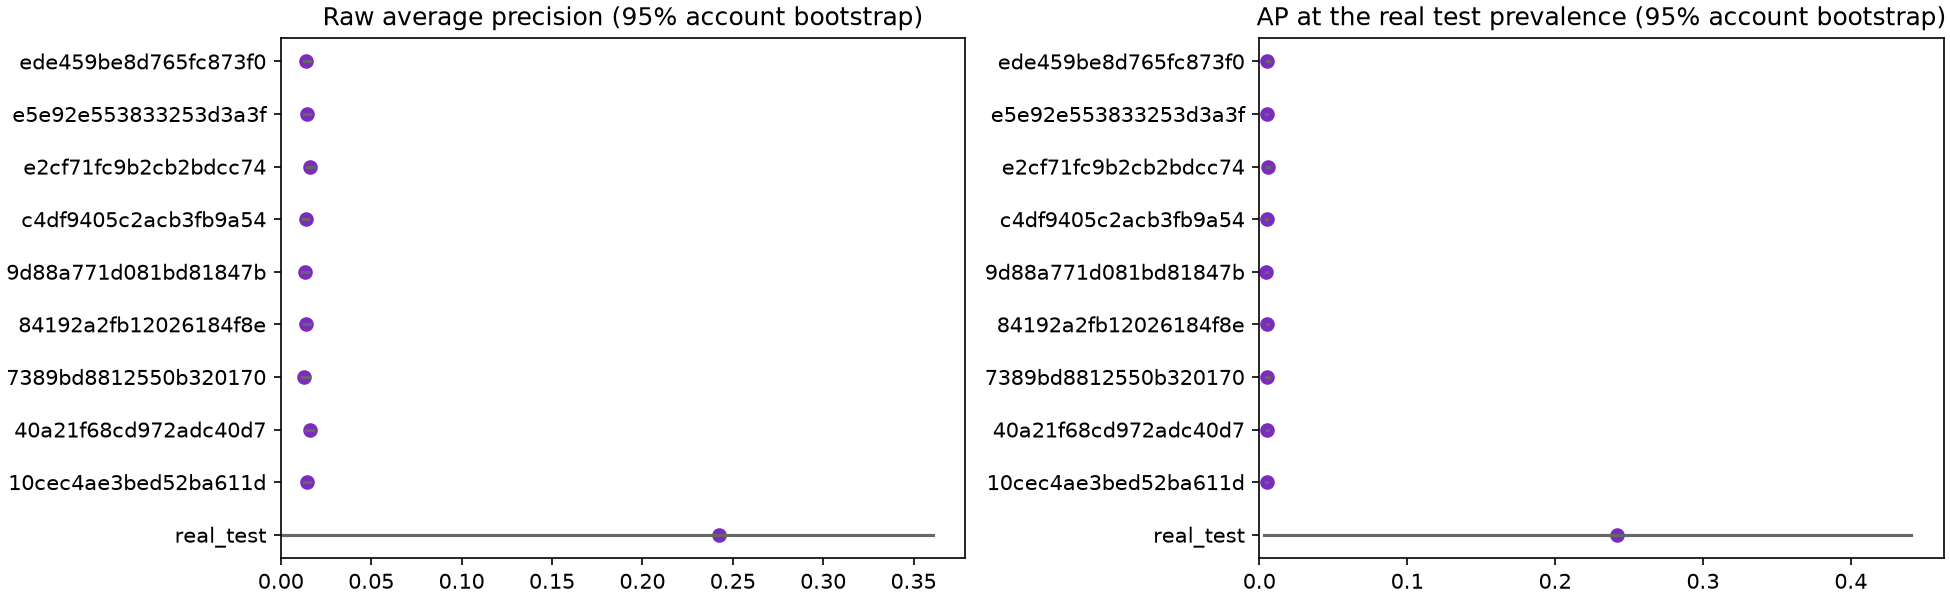

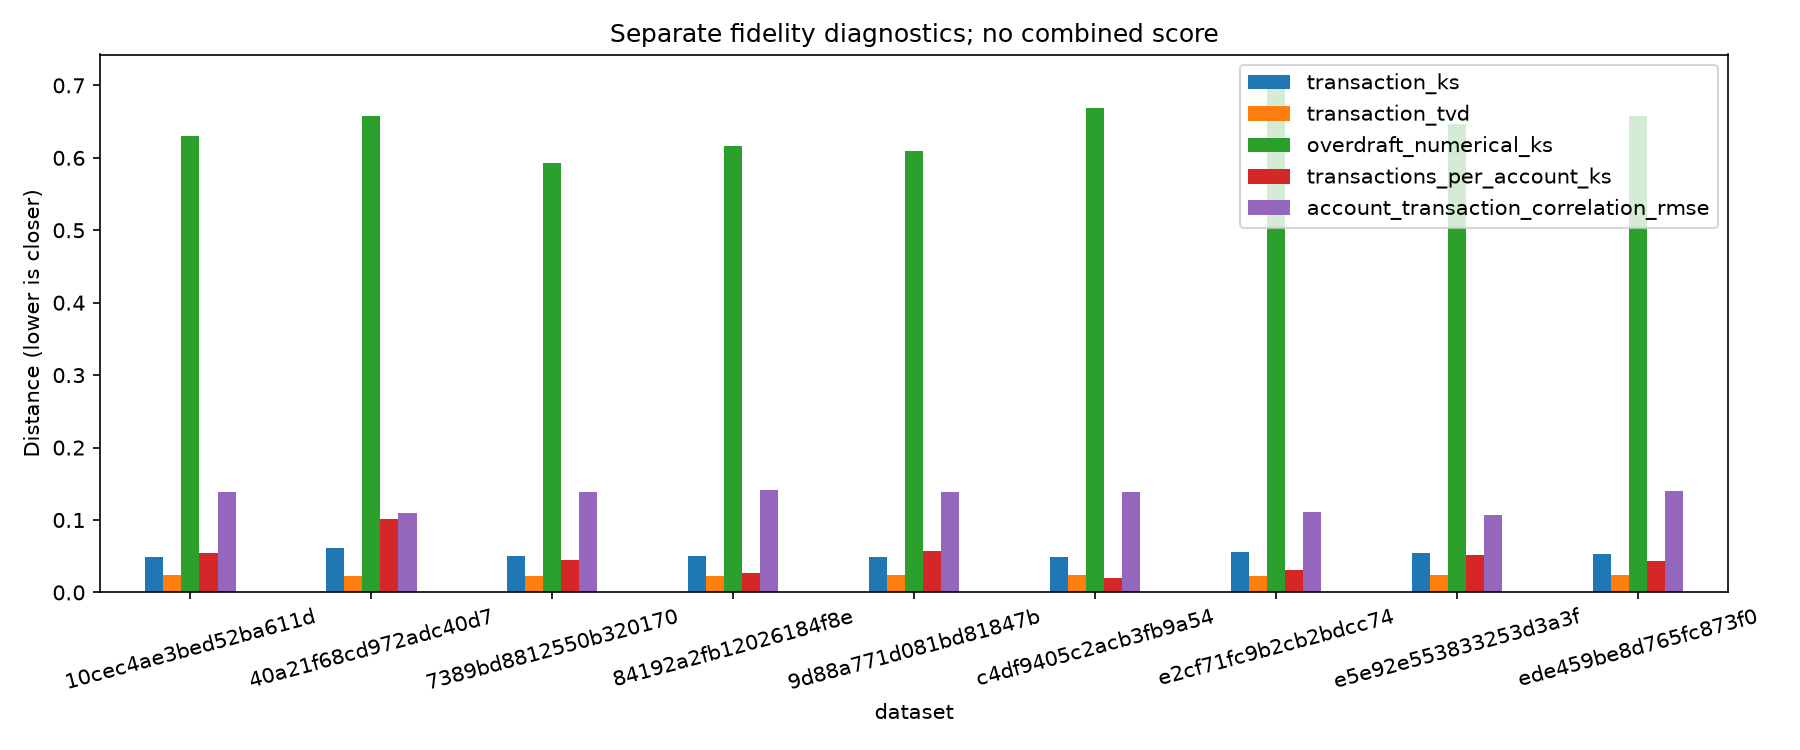

Completed 9 of 9 requested seed/configuration pairs.
Full multi-table quality — separate from overdraft transfer:


,all_table_count,all_edge_count,all_table_numerical_ks,all_table_categorical_tvd,all_cardinality_ks,all_relationship_correlation_rmse,all_min_fk_valid_rate,all_min_pk_unique_rate,multi_parent_correlation_rmse,multi_parent_joint_categorical_tvd,all_undefined_distribution_columns,all_undefined_correlation_pairs
dataset,,,,,,,,,,,,
10cec4ae3bed52ba611d,8.0,8.0,0.1216,0.0926,0.0431,NaN,0.9839,1.0,0.0349,0.1462,0.0,2.0
40a21f68cd972adc40d7,8.0,8.0,0.1104,0.0992,0.0812,NaN,1.0000,1.0,0.0345,0.1600,0.0,2.0
7389bd8812550b320170,8.0,8.0,0.0930,0.0999,0.0647,NaN,1.0000,1.0,0.0118,0.1435,0.0,2.0
84192a2fb12026184f8e,8.0,8.0,0.1099,0.1079,0.0675,NaN,1.0000,1.0,0.0108,0.1478,0.0,2.0
9d88a771d081bd81847b,8.0,8.0,0.0951,0.1059,0.0352,NaN,1.0000,1.0,0.0176,0.1671,0.0,2.0
c4df9405c2acb3fb9a54,8.0,8.0,0.0966,0.0968,0.0553,NaN,0.8667,1.0,0.0225,0.1507,0.0,2.0
e2cf71fc9b2cb2bdcc74,8.0,8.0,0.1110,0.1111,0.0867,NaN,1.0000,1.0,0.0445,0.1888,0.0,2.0
e5e92e553833253d3a3f,8.0,8.0,0.0900,0.1114,0.0550,NaN,1.0000,1.0,0.0173,0.1543,0.0,2.0
ede459be8d765fc873f0,8.0,8.0,0.1041,0.0907,0.0761,NaN,0.9266,1.0,0.0086,0.1451,0.0,2.0


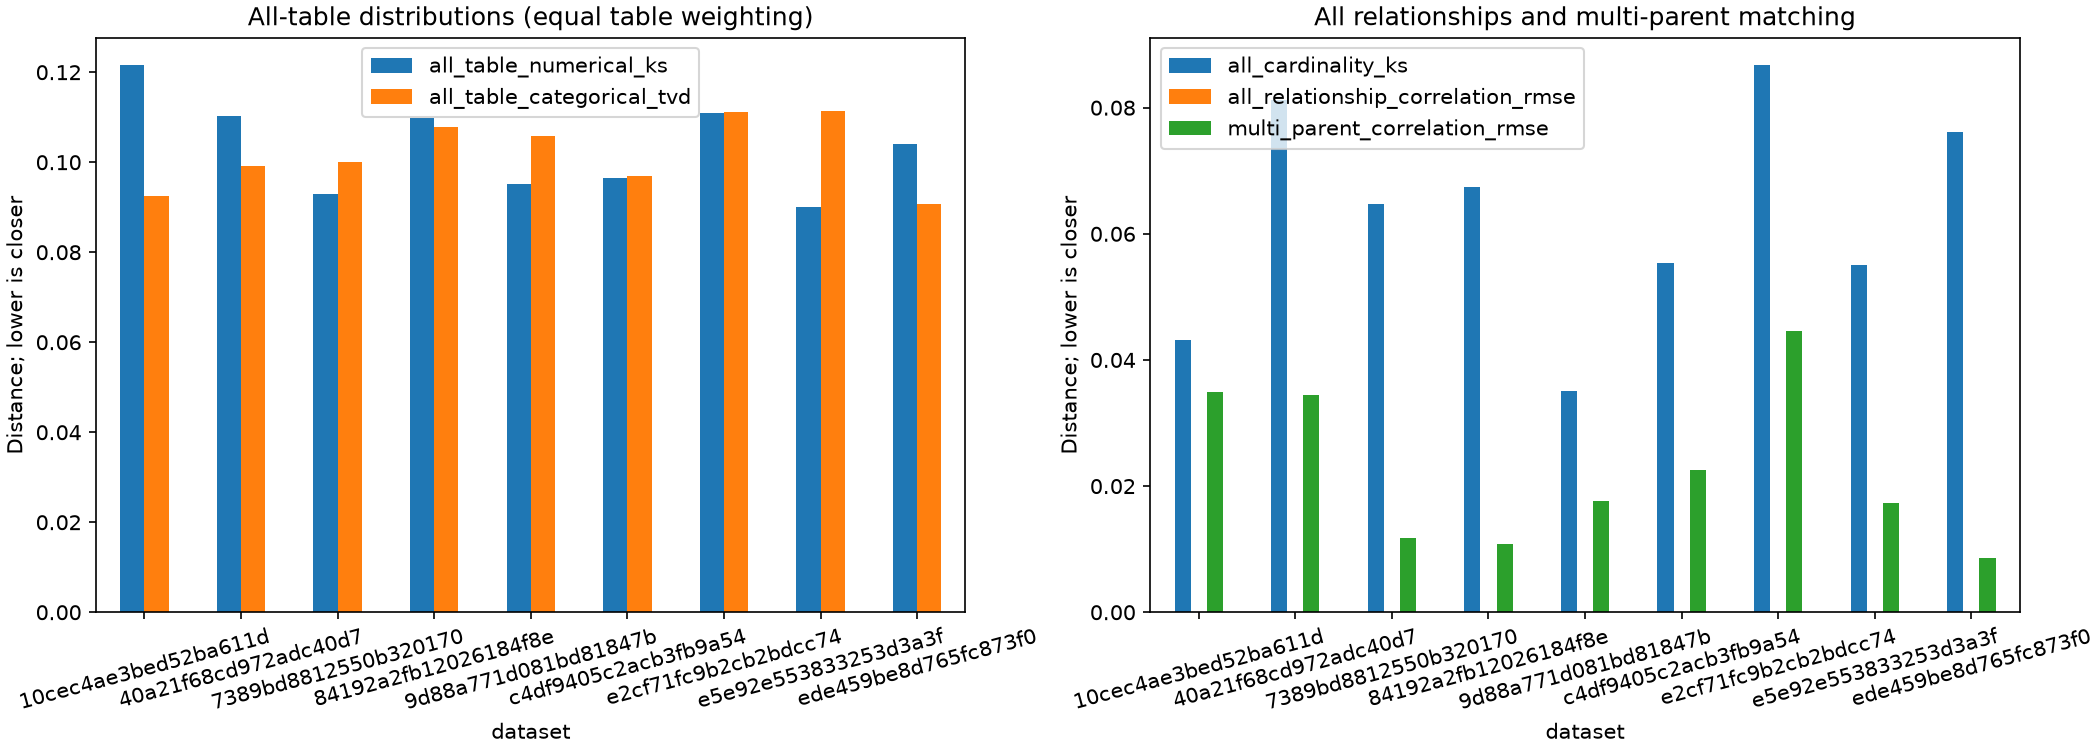

In [5]:
RUN_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=TRIALS) if DATA_DIR.is_dir() else []
comparison = None
REPORT_DIR = None
if RUN_DIRS:
    comparison, REPORT_DIR = evaluate_saved_runs(DATA_DIR, RUN_DIRS, OUTPUT_ROOT, bootstrap_repetitions=200)
    section, field = PARAMETER.split(".")
    parameter_values = {}
    for run in RUN_DIRS:
        saved = yaml.safe_load((run / "config.yaml").read_text())
        parameter_values[run.name] = str(saved[section][field])
    comparison.insert(0, "parameter_value", pd.Series(parameter_values))
    TRANSFER_AND_QUALITY = [
        "average_precision", "average_precision_low", "average_precision_high",
        "standardized_ap", "overdraft_prevalence", "transaction_ks", "transaction_tvd",
        "overdraft_numerical_ks", "synthetic_transaction_before_account_rate",
    ]
    show(comparison[["parameter_value", *TRANSFER_AND_QUALITY]].round(4))
    print(f"Detailed report: {REPORT_DIR}")
    show(Image(filename=str(REPORT_DIR / "transfer_intervals.png")))
    show(Image(filename=str(REPORT_DIR / "quality_comparison.png")))
    print(f"Completed {len(RUN_DIRS)} of {len(TRIALS)} requested seed/configuration pairs.")
else:
    print("No completed results for this experiment. Start with 01_baseline.ipynb.")

if comparison is not None:
    FULL_TABLE_COLUMNS = [
        "all_table_count", "all_edge_count", "all_table_numerical_ks", "all_table_categorical_tvd",
        "all_cardinality_ks", "all_relationship_correlation_rmse", "all_min_fk_valid_rate",
        "all_min_pk_unique_rate", "multi_parent_correlation_rmse", "multi_parent_joint_categorical_tvd",
        "all_undefined_distribution_columns", "all_undefined_correlation_pairs",
    ]
    print("Full multi-table quality — separate from overdraft transfer:")
    show(comparison.loc[comparison.index != "real_test", FULL_TABLE_COLUMNS].round(4))
    show(Image(filename=str(REPORT_DIR / "multi_table_quality.png")))


## 5. Conclusion — cluster count (2026-11-12)

**Decision: keep 50 clusters. 10 and 25 showed no consistent gain. They were not retested with new training seeds, and retraining alone moves these metrics more than the differences seen here.**

**Setup:** 10, 25, 50 (baseline) × sampling seeds 42/43/44 (9 runs). Each value retrains clustering and every model **once** (training seed 42); the 3 seeds vary generation only. Values are mean ± sd over the 3 sampling seeds.

| Clusters | Standardized AP ↑ | ROC-AUC ↑ | Accounts (real 500) | Transactions (real 117,560) | Min FK validity | Cardinality KS ↓ | Accounts ever overdrawn | Transactions before opening |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 10 | 0.0050 ± 0.0001 | 0.760 ± 0.005 | 443 | 105,706 | 0.950 ± 0.073 | 0.045 | 63.0% | 24.2% |
| 25 | 0.0052 ± 0.0001 | 0.754 ± 0.008 | 635 | 150,936 | 0.976 ± 0.042 | 0.069 | 58.8% | 22.9% |
| **50 (baseline)** | 0.0054 ± 0.0003 | 0.763 ± 0.007 | 465 | 114,050 | 1.000 | 0.074 | 62.6% | 18.9% |

**Real reference:** test AP 0.2422, ROC-AUC 0.8722; 5.6% of accounts ever overdrawn; 0% of transactions before opening.

- **Differences are smaller than retraining noise.** In the parent-weight and clustering-method training-seed checks, baseline ROC-AUC spans 0.614–0.769 across training seeds (sd 0.081). Every difference here is within that range.
- **Fewer clusters: better cardinality, worse chronology.** 10 clusters gave the best cardinality KS (0.045), but 24% of transactions came before account opening (baseline 18.9%), and standardized AP was slightly lower.
- **25 clusters inflated sizes** at this training seed: 27% more accounts and 28% more transactions than the real cohort.
- **Orphan cards are not a cluster-count effect.** 10 clusters left 10 and 1, and 25 clusters left 8, but the baseline also produced 11 at training seed 43. The cause is a multi-parent matching bug; see [PROGRESS.md](../../docs/PROGRESS.md).
- **No value fixes** overdraft concentration (59–63% vs real 5.6%) or chronology.

**Next:** none for cluster count. If revisited after the orphan-card and date-representation fixes, use 3 training seeds paired by seed.

Report: [comparison.csv](../../../results/experiments/transaction_overdraft_from_scratch/6280291d14dc3a69/comparison.csv) · [transfer intervals](../../../results/experiments/transaction_overdraft_from_scratch/6280291d14dc3a69/transfer_intervals.png) · [full-table quality](../../../results/experiments/transaction_overdraft_from_scratch/6280291d14dc3a69/multi_table_quality.png)